# Solutions · 07 · Energy balances and adiabatic reactors

Worked solutions to the exercises of [notebook 07](../notebooks/07_energy_balances_and_adiabatic_reactors.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize
from engreact import energy, kinetics, thermo
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Exercise 1

Ammonia synthesis with a stoichiometric feed at 200 bar: compute the equilibrium conversion curve X_e(T) from `thermo` between 600 and 900 K, draw the adiabatic line from 650 K (Delta T_ad about 200 K per unit conversion), and read the maximum single-bed conversion. How many beds with cooling to 650 K reach 25 % conversion?

equilibrium conversion: 0.586 at 650 K, 0.343 at 750 K, 0.177 at 850 K
an adiabatic bed from 650 K reaches the equilibrium curve at X = 0.391 (T = 728 K)
  bed 1: X = 0.391
  bed 2: X = 0.520
  bed 3: X = 0.564
3 beds with interstage cooling to 650 K reach X = 0.564


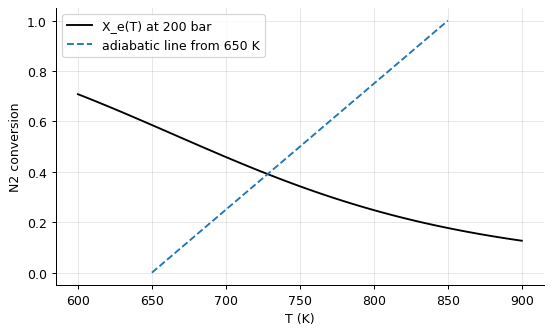

In [2]:
stoich = {"N2": -1, "H2": -3, "NH3": 2}
p = 200.0
def X_eq(T):
    Kp = thermo.equilibrium_constant(stoich, T)
    def f(X):
        n = 4 - 2 * X                                                        # total moles per mole of N2 fed
        y_N2, y_H2, y_NH3 = (1 - X) / n, 3 * (1 - X) / n, 2 * X / n
        return (y_NH3 * p) ** 2 / ((y_N2 * p) * (y_H2 * p) ** 3) - Kp
    return optimize.brentq(f, 1e-9, 1 - 1e-9)
T = np.linspace(600, 900, 61)
Xe = np.array([X_eq(t) for t in T])
dT_ad = 200.0
T_line = 650.0 + np.linspace(0, 1, 100) * dT_ad
X_line = np.linspace(0, 1, 100)
cross = optimize.brentq(lambda X: X_eq(650.0 + X * dT_ad) - X, 1e-6, 0.999)
print(f"equilibrium conversion: {X_eq(650):.3f} at 650 K, {X_eq(750):.3f} at 750 K, {X_eq(850):.3f} at 850 K")
print(f"an adiabatic bed from 650 K reaches the equilibrium curve at X = {cross:.3f} (T = {650 + cross*dT_ad:.0f} K)")
X, beds = 0.0, 0
while X < 0.55 and beds < 10:
    X = optimize.brentq(lambda Xo: X_eq(650.0 + (Xo - X) * dT_ad) - Xo, X + 1e-6, 0.999); beds += 1
    print(f"  bed {beds}: X = {X:.3f}")
print(f"{beds} beds with interstage cooling to 650 K reach X = {X:.3f}")
plt.plot(T, Xe, "k", label="X_e(T) at 200 bar"); plt.plot(T_line, X_line, "--", label="adiabatic line from 650 K"); plt.xlabel("T (K)"); plt.ylabel("N2 conversion"); plt.legend(); plt.show()

At 200 bar the equilibrium conversion falls from 59 % at 650 K to 18 % at 850 K; the adiabatic line from
650 K meets the curve at 39 % and 728 K, and each further bed adds less as the operating point climbs the
curve: 55 % needs three beds. Industrial converters use three or four beds and a recycle, because the last
few percent cost the most.

## Exercise 2

An endothermic first-order reaction (Ea = 90 kJ/mol, Delta H = +80 kJ/mol) is run in a PFR heated by a jacket at 750 K with Ua = 500 W/(m3 K). Using `energy.pfr_heat_exchange`, find the reactor volume for 80 % conversion and compare with the adiabatic case.

In [3]:
k0e, Eae, dHe, C_A0, cp_vol = 2e4, 90e3, 80e3, 2500.0, 3.6e6
F_A0 = 2.5
rate_e = lambda X, T: kinetics.arrhenius(k0e, Eae, T) * C_A0 * (1 - X)
def outlet(V, Ua):
    if Ua == 0:
        return energy.adiabatic_pfr(rate_e, F_A0, V, 750.0, dHe, sum_theta_cp=cp_vol / C_A0)["X"][-1]
    return energy.pfr_heat_exchange(rate_e, F_A0, V, 750.0, dHe, sum_F_cp=F_A0 * cp_vol / C_A0, Ua=Ua, T_a=750.0)["X"][-1]
for Ua, label in ((0.0, "adiabatic"), (5e3, "jacket 750 K, Ua = 5e3"), (5e4, "jacket 750 K, Ua = 5e4"), (5e5, "jacket 750 K, Ua = 5e5")):
    V80 = optimize.brentq(lambda V: outlet(V, Ua) - 0.8, 1e-3, 200.0)
    print(f"{label:<26}: volume for 80 % conversion = {V80:.3f} m3")

adiabatic                 : volume for 80 % conversion = 0.270 m3


jacket 750 K, Ua = 5e3    : volume for 80 % conversion = 0.249 m3
jacket 750 K, Ua = 5e4    : volume for 80 % conversion = 0.191 m3


jacket 750 K, Ua = 5e5    : volume for 80 % conversion = 0.155 m3


Adiabatically the endothermic reaction cools itself by 55 K and slows; a jacket at the feed temperature helps
only when its capacity is comparable with the reaction's heat demand of several hundred kW per cubic metre -
an ordinary jacket (Ua of a few thousand W/(m3 K)) changes almost nothing, furnace-tube heat transfer
(10^5 W/(m3 K)) keeps the reactor nearly isothermal and cuts the volume. Endothermic reactors are heat-transfer
equipment with catalyst in it.

## Exercise 3

**Implement it yourself:** integrate the adiabatic PFR yourself with solve_ivp, substituting the energy balance for T(X) inside the rate, and reproduce `energy.adiabatic_pfr` for T0 = 300 K.

In [4]:
from scipy import integrate
k0, Ea, dH = 5.0e7, 68e3, -250e3
dT_ad_ = energy.adiabatic_temperature_rise(dH, C_A0, cp_vol)
sol = integrate.solve_ivp(lambda v, X: [kinetics.arrhenius(k0, Ea, 300.0 + X[0] * dT_ad_) * C_A0 * (1 - X[0]) / F_A0], (0, 0.3), [0.0], method="LSODA", rtol=1e-9)
lib = energy.adiabatic_pfr(lambda X, T: kinetics.arrhenius(k0, Ea, T) * C_A0 * (1 - X), F_A0, 0.3, 300.0, dH, sum_theta_cp=cp_vol / C_A0)
print(f"by hand: X = {sol.y[0][-1]:.5f}; library: {lib['X'][-1]:.5f}")

by hand: X = 0.02610; library: 0.02610


Substituting $T(X)$ from the energy balance into the rate turns the adiabatic PFR into a single ODE in X;
the library does the same and the two agree to five digits.